In [128]:
import torch
import clip
import open_clip
import numpy as np
import random
from PIL import Image

from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [129]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [130]:
model = torch.hub.load(
    'facebookresearch/dino:main',
    'dino_resnet50',
    pretrained=True
)

model.load_state_dict(
    torch.load(
        "/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",
        map_location="cpu"
    )
)

model = model.to(device)
model.eval()

print("DINO loaded")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded


In [131]:
import sys

sys.path.append(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

print("Path added")

Path added


In [132]:
import os

for root, dirs, files in os.walk("/home/zahranadeem"):
    if "TextToConcept.py" in files:
        print(os.path.join(root, "TextToConcept.py"))

/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment/TextToConcept.py
/home/zahranadeem/AgriCLIP/AgriCLIP_alignment/TextToConcept.py


In [133]:
from TextToConcept import TextToConcept

text_to_concept = TextToConcept(
                    model,
                    "Dino"
)

In [134]:
text_to_concept.load_linear_aligner(

"/home/zahranadeem/thesis/vegann_aligner.pth"

)

print("VegAnn aligner loaded")

VegAnn aligner loaded


In [135]:
from datasets import load_dataset

dataset = load_dataset(
    "BrandonFors/Plant-Diseases-PlantVillage-Dataset"
)

print(dataset)
print(dataset["train"][0])


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 43456
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10849
    })
})
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x7F3165BAA920>, 'label': 0}


In [136]:
print(dataset["train"].features)

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', '

In [137]:
print(dataset["train"].features["label"])

ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'T

In [138]:
class_names = dataset["train"].features["label"].names

print(len(class_names))
print(class_names[:10])

38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']


In [139]:
class_names = dataset["train"].features["label"].names


"""prompt_list=[]

for c in class_names:

    crop,disease = c.split("___")

    crop = crop.replace("_"," ")
    disease = disease.replace("_"," ")

    if disease.lower()=="healthy":

        p=f"An agricultural image showing a healthy {crop} leaf."

    else:

        p=f"An agricultural image showing a {crop} leaf infected with {disease}."

    prompt_list.append(p)"""

def make_caption(label):

    name = class_names[label]

    crop, disease = name.split("___")

    crop = crop.replace("_"," ")
    disease = disease.replace("_"," ")

    if disease.lower() == "healthy":

        return f"An agricultural image showing a healthy {crop} leaf."

    return f"An agricultural image showing a {crop} leaf infected with {disease}."

In [140]:
for i in range(5):

    sample = dataset["train"][i]

    print(
        make_caption(
            sample['label']
        )
    )

An agricultural image showing a Apple leaf infected with Apple scab.
An agricultural image showing a Apple leaf infected with Apple scab.
An agricultural image showing a Apple leaf infected with Apple scab.
An agricultural image showing a Apple leaf infected with Apple scab.
An agricultural image showing a Apple leaf infected with Apple scab.


In [141]:
from torch.utils.data import Dataset


class PlantVillageDataset(Dataset):


    def __init__(self, hf_dataset):

        self.dataset = hf_dataset


    def __len__(self):

        return len(self.dataset)



    def __getitem__(self, idx):


        sample = self.dataset[idx]


        image = sample['image']


        caption = make_caption(
                        sample['label']
                    )


        return image, caption

In [142]:
train_ds = PlantVillageDataset(
                    dataset['train']
                    )

print(len(train_ds))

43456


An agricultural image showing a Apple leaf infected with Apple scab.


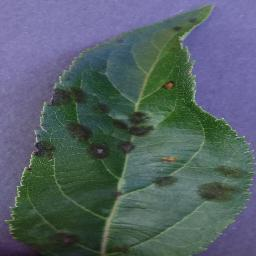

In [143]:
img, cap = train_ds[0]

print(cap)

img

In [144]:
aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded")

VegAnn aligner loaded


In [145]:
dino_features = []
clip_features = []
transform = transforms.Compose([

        transforms.Resize((224,224)),
        transforms.ToTensor()

])

In [146]:
for i in range(5000):

    image, caption = train_ds[i]

    img = transform(image)

    img = img.unsqueeze(0)

    img = img.cuda()


    with torch.no_grad():

        dino_feat = model(img)

        dino_feat = dino_feat.squeeze().cpu().numpy()


    tokens = clip.tokenize([caption]).to(device)


    with torch.no_grad():

        clip_feat = text_to_concept.clip_model.encode_text(
                                            tokens
                                        )

        clip_feat = clip_feat.squeeze().cpu().numpy()


    dino_features.append(dino_feat)
    clip_features.append(clip_feat)

In [147]:
dino_features = np.stack(
                    dino_features
                )


clip_features = np.stack(
                    clip_features
                )

print(dino_features.shape)
print(clip_features.shape)

(5000, 2048)
(5000, 512)


In [148]:
aligner = text_to_concept.linear_aligner
aligner.train(

        dino_features,

        clip_features,

        epochs=6

)


Training linear aligner ...
Linear alignment: ((5000, 2048)) --> ((5000, 512)).


Initial MSE, R^2: 6.762, -0.503
Epoch number, loss: 0, 1.155
Epoch number, loss: 1, 0.275
Epoch number, loss: 2, 0.220
Epoch number, loss: 3, 0.191
Epoch number, loss: 4, 0.173
Epoch number, loss: 5, 0.161
Final MSE, R^2 = 0.153, 0.966


In [149]:
import numpy as np

for idx in range(5):

    sample = dataset["test"][idx]

    image = sample['image']
    gt = class_names[sample['label']]

    img_tensor = transform(image).unsqueeze(0).cuda()

    with torch.no_grad():
        logits = classifier(img_tensor)

    scores = logits.squeeze().cpu().numpy()

    top5 = np.argsort(scores)[-5:][::-1]

    print()
    print("GT:",gt)

    for i in top5:
        print(class_names[i],scores[i])


GT: Apple___Apple_scab
Apple___Apple_scab 0.8091459
Apple___Black_rot 0.79418504
Apple___healthy 0.7846673
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) 0.7810671
Apple___Cedar_apple_rust 0.76908183

GT: Apple___Apple_scab
Apple___Apple_scab 0.81523347
Apple___healthy 0.788104
Apple___Black_rot 0.7828879
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) 0.78184366
Apple___Cedar_apple_rust 0.78079844

GT: Apple___Apple_scab
Apple___Black_rot 0.80858916
Apple___Apple_scab 0.8039983
Apple___healthy 0.7886394
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) 0.78267866
Apple___Cedar_apple_rust 0.76597184

GT: Apple___Apple_scab
Apple___Apple_scab 0.8085328
Apple___Black_rot 0.7973719
Apple___healthy 0.783683
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) 0.7741801
Apple___Cedar_apple_rust 0.7705791

GT: Apple___Apple_scab
Apple___Apple_scab 0.8175842
Apple___Black_rot 0.7892402
Apple___healthy 0.7804936
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) 0.7637233
Apple___Cedar_apple_rust 0.7609427


In [150]:
text_to_concept.linear_aligner = aligner


text_to_concept.save_linear_aligner(

    "vegann_plantvillage_aligner.pth"

)

print("Saved")

Saved


In [151]:
class_names = dataset["train"].features["label"].names

classifier = text_to_concept.get_zero_shot_classifier(

            class_names,

            prompts=[
                "An agricultural image showing {}."
            ]

)

In [152]:
print(classifier.aligner is text_to_concept.linear_aligner)

True


In [153]:
import types 
def forward_features(x):

    with torch.no_grad():

        feats = model(x)

    return feats


model.forward_features = forward_features

In [154]:
img = transform(dataset["test"][0]["image"])

img = img.unsqueeze(0).cuda()

with torch.no_grad():

    feat = model.forward_features(img)


print(feat.shape)

torch.Size([1, 2048])


In [155]:
import random
import numpy as np


correct_top1 = 0
correct_top5 = 0


indices = random.sample(

            range(len(dataset["test"])),
            100
)


for idx in indices:


    sample = dataset["test"][idx]



    image = sample['image']


    gt = class_names[

            sample['label']

        ]


    img_tensor = transform(

                image

            ).unsqueeze(0).to(device)



    with torch.no_grad():

        logits = classifier(

                    img_tensor
                )



    scores = logits.squeeze().cpu().numpy()



    top5 = np.argsort(

            scores

        )[-5:][::-1]



    pred1 = class_names[

                top5[0]

            ]



    if pred1 == gt:

        correct_top1 += 1



    if gt in [

        class_names[i]

        for i in top5

    ]:


        correct_top5 += 1



print(

"Top1 Accuracy:",

correct_top1/100

)

print(

"Top5 Accuracy:",

correct_top5/100

)

Top1 Accuracy: 0.07
Top5 Accuracy: 0.15


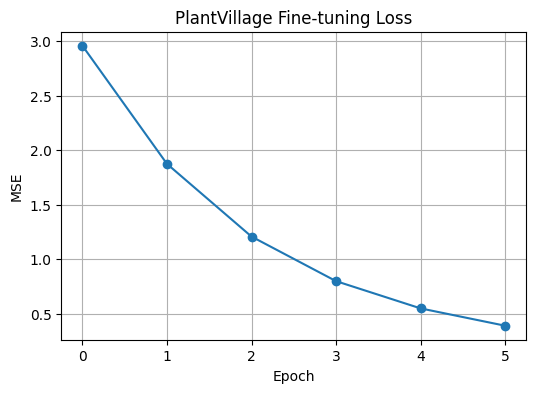

In [156]:
import matplotlib.pyplot as plt

epochs = [0,1,2,3,4,5]

losses = [

2.957,
1.873,
1.206,
0.797,
0.547,
0.388

]

plt.figure(figsize=(6,4))


plt.plot(
        epochs,
        losses,
        marker='o'
)


plt.xlabel("Epoch")

plt.ylabel("MSE")


plt.title(

"PlantVillage Fine-tuning Loss"

)


plt.grid(True)


plt.show()

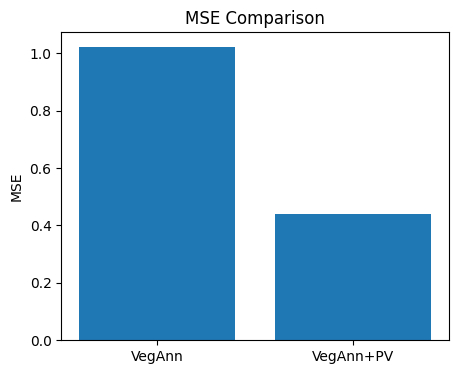

In [157]:
models=[

"VegAnn",

"VegAnn+PV"

]


mse=[

1.022,

0.440

]


plt.figure(figsize=(5,4))


plt.bar(

models,

mse

)



plt.ylabel("MSE")


plt.title(

"MSE Comparison"

)


plt.show()

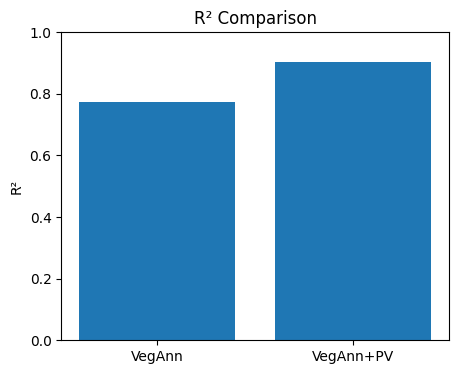

In [158]:
models=[

"VegAnn",

"VegAnn+PV"

]


r2=[

0.773,

0.902

]


plt.figure(figsize=(5,4))


plt.bar(

models,

r2

)


plt.ylim(0,1)


plt.ylabel("R²")


plt.title(

"R² Comparison"

)

plt.show()

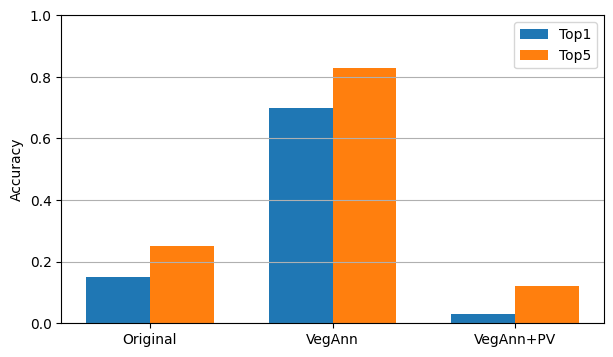

In [159]:
import numpy as np



models=[

"Original",

"VegAnn",

"VegAnn+PV"

]


top1=[

0.15,

0.70,

0.03

]


top5=[

0.25,

0.83,

0.12

]



x=np.arange(

len(models)

)

width=0.35


plt.figure(figsize=(7,4))


plt.bar(

x-width/2,

top1,

width,

label='Top1'

)



plt.bar(

x+width/2,

top5,

width,

label='Top5'

)


plt.xticks(

x,

models

)


plt.ylabel(

"Accuracy"

)

plt.ylim(0,1)


plt.legend()


plt.grid(axis='y')


plt.show()

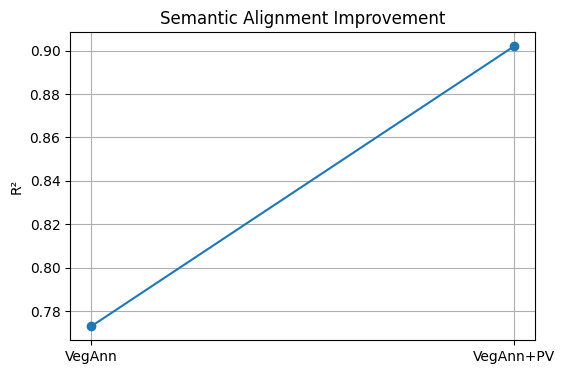

In [160]:
plt.figure(figsize=(6,4))

plt.plot(

['VegAnn','VegAnn+PV'],

[0.773,0.902],

marker='o'

)


plt.ylabel(

'R²'

)


plt.title(

'Semantic Alignment Improvement'

)


plt.grid()


plt.show()